# Bayesian Inference for Heart Disease Diagnosis

**Assignment 3 – Enhancing a Medical Diagnosis System with Bayesian Inference**

This notebook builds a small diagnostic engine that answers one question for each patient:
*given what we already know about coronary artery disease and what this patient's tests show,
how likely is it that they have the disease, and how sure are we?*

Workflow:

1. **Data collection and preprocessing** – UCI Heart Disease data (Cleveland as the main cohort).
2. **Prior knowledge** – prevalence and risk-factor effects taken from published studies.
3. **Model development** – Bayesian logistic regression in PyMC (NUTS sampler).
4. **Validation** – 20% held-out test set: accuracy, log-likelihood, confusion matrix, ROC/AUC, calibration.
5. **Iteration and refinement** – prior-data conflict check, adjusted priors, robust likelihood, LOO comparison, cross-validation.
6. **Dynamic updating** – the posterior after one batch of patients becomes the prior for the next.

Reusable functions live in `bayes_heart.py` so the notebook reads as a story. All figures go to
`figures/` and all result tables to `results/`; the Word report is built from those files.

## 0. Setup

In [1]:
import json
import logging
import warnings
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.model_selection import StratifiedKFold

import bayes_heart as bh

warnings.filterwarnings("ignore")
logging.getLogger("pymc").setLevel(logging.ERROR)

SEED = 42
DATA, FIG, RES = Path("data"), Path("figures"), Path("results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

# One colour per model, used the same way in every figure.
COL = {"MLE": "#8a8984", "M1": "#2a78d6", "M2": "#eb6834",
       "M3": "#1baf7a", "M4": "#6250d6", "prior": "#8a8984"}
INK, MUTED = "#2b2b2b", "#6b6a66"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": "#bdbcb6", "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")

print("PyMC", bh.pm.__version__, "| ArviZ", az.__version__)

PyMC 5.28.5 | ArviZ 0.22.0


## 1. Data collection and preprocessing

The UCI Heart Disease archive (Janosi et al., 1989) holds patients referred for coronary angiography at
four centres. The outcome `num` is the angiographic result (0 = less than 50% narrowing of any major
vessel, 1–4 = disease). Like most work on this dataset we turn it into a binary label: **disease present (num > 0)**.

Thirteen predictors are available: age, sex, chest-pain type (`cp`), resting blood pressure (`trestbps`),
cholesterol (`chol`), fasting blood sugar > 120 mg/dl (`fbs`), resting ECG (`restecg`), maximum heart rate
(`thalach`), exercise-induced angina (`exang`), ST depression on exercise (`oldpeak`), slope of the peak
exercise ST segment (`slope`), number of vessels coloured by fluoroscopy (`ca`) and thallium scan result (`thal`).

In [2]:
all_sites = bh.load_all_sites(DATA)
site_summary = (all_sites.groupby("site")
                .agg(patients=("target", "size"), with_disease=("target", "sum"),
                     prevalence=("target", "mean"),
                     missing_ca=("ca", lambda s: s.isna().mean()),
                     missing_thal=("thal", lambda s: s.isna().mean()))
                .sort_values("prevalence"))
site_summary.to_csv(RES / "site_summary.csv")
site_summary.round(3)

,patients,with_disease,prevalence,missing_ca,missing_thal
site,,,,,
Hungary,294,106,0.361,0.990,0.905
Cleveland,303,139,0.459,0.013,0.007
Long Beach VA,200,149,0.745,0.990,0.830
Switzerland,123,115,0.935,0.959,0.423


Cleveland is the only site where the key test results (`ca`, `thal`) are nearly complete, so it is the
main modelling cohort. The other sites are still useful: their very different disease rates are a
reminder that the base rate depends on *who gets referred*, which matters when choosing a prior.

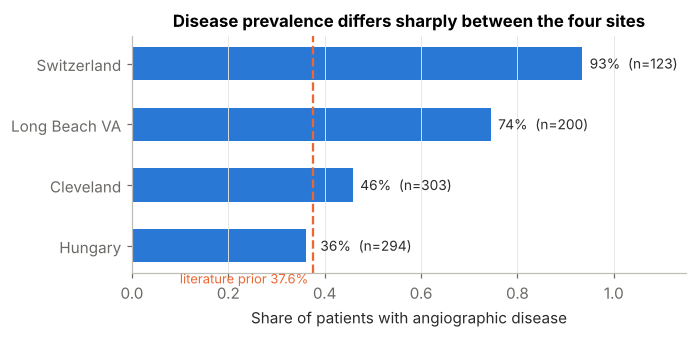

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
s = site_summary.sort_values("prevalence")
ax.barh(s.index, s["prevalence"], color=COL["M1"], height=0.55)
for i, (p, n) in enumerate(zip(s["prevalence"], s["patients"])):
    ax.text(max(p, bh.PRIOR_PREVALENCE) + 0.015, i, f"{p:.0%}  (n={n})", va="center", color=INK, fontsize=9)
ax.axvline(bh.PRIOR_PREVALENCE, color=COL["M2"], ls="--", lw=1.5)
ax.text(bh.PRIOR_PREVALENCE - 0.01, -0.62, "literature prior 37.6%", color=COL["M2"], fontsize=8.5, ha="right")
ax.set_xlim(0, 1.15); ax.set_xlabel("Share of patients with angiographic disease")
ax.set_title("Disease prevalence differs sharply between the four sites")
ax.grid(axis="y", visible=False)
save(fig, "fig01_prevalence_by_site"); plt.show()

### 1.1 Exploring the Cleveland cohort

In [4]:
cle = bh.load_site(DATA / "processed.cleveland.data")
print(cle.shape)
print("Missing values per column:\n", cle.isna().sum()[lambda s: s > 0])
print(f"Disease prevalence: {cle['target'].mean():.1%}")
cle.describe().T.round(2)

(303, 15)
Missing values per column:
 ca      4
thal    2
dtype: int64
Disease prevalence: 45.9%


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


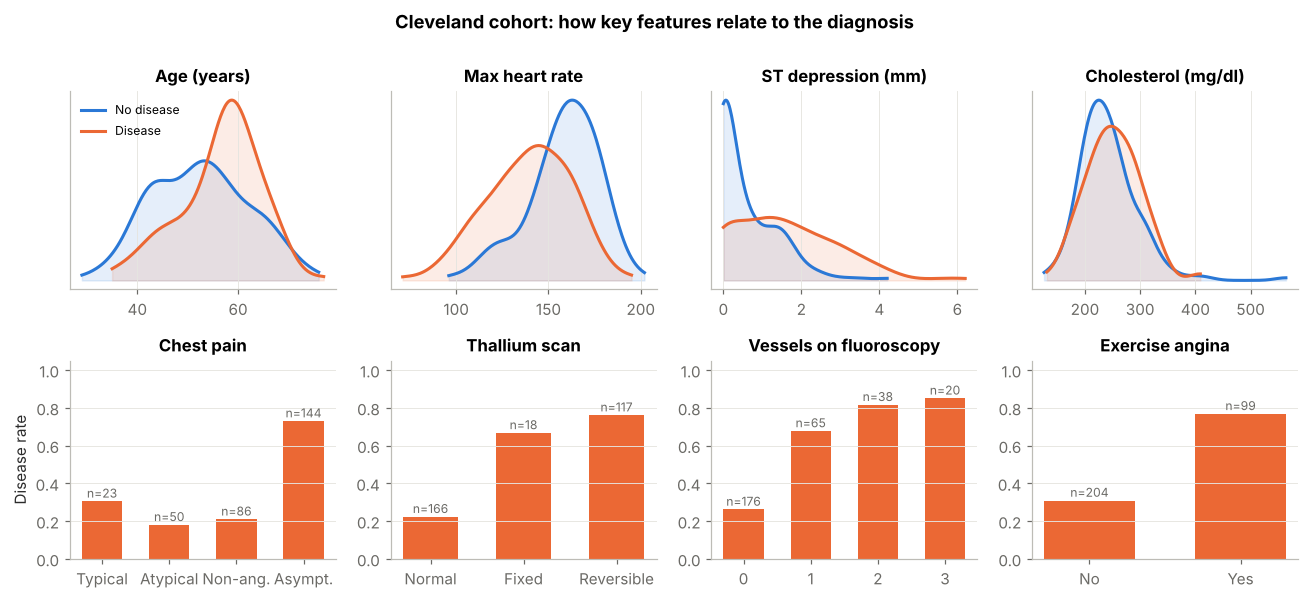

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4))
labels = {0: "No disease", 1: "Disease"}
for ax, col, title in zip(axes[0], ["age", "thalach", "oldpeak", "chol"],
                          ["Age (years)", "Max heart rate", "ST depression (mm)", "Cholesterol (mg/dl)"]):
    for t, c in [(0, COL["M1"]), (1, COL["M2"])]:
        v = cle.loc[cle["target"] == t, col].dropna()
        kde = stats.gaussian_kde(v)
        xs = np.linspace(v.min(), v.max(), 200)
        ax.plot(xs, kde(xs), color=c, label=labels[t])
        ax.fill_between(xs, kde(xs), color=c, alpha=0.12)
    ax.set_title(title); ax.set_yticks([])
axes[0, 0].legend(loc="upper left", fontsize=8)

cat_maps = {
    "cp": ("Chest pain", {1: "Typical", 2: "Atypical", 3: "Non-ang.", 4: "Asympt."}),
    "thal": ("Thallium scan", {3: "Normal", 6: "Fixed", 7: "Reversible"}),
    "ca": ("Vessels on fluoroscopy", {0: "0", 1: "1", 2: "2", 3: "3"}),
    "exang": ("Exercise angina", {0: "No", 1: "Yes"}),
}
for ax, (col, (title, m)) in zip(axes[1], cat_maps.items()):
    g = cle.groupby(col)["target"].agg(["mean", "size"])
    ax.bar([m[k] for k in g.index], g["mean"], color=COL["M2"], width=0.6)
    for i, (p, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, p + 0.02, f"n={n}", ha="center", fontsize=8, color=MUTED)
    ax.set_ylim(0, 1.05); ax.set_title(title); ax.set_ylabel("Disease rate" if col == "cp" else "")
    ax.grid(axis="x", visible=False)
fig.suptitle("Cleveland cohort: how key features relate to the diagnosis", fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "fig02_eda_cleveland"); plt.show()

A few things stand out before any modelling:

* Exercise-test and imaging results (ST depression, thallium defects, number of calcified vessels) separate the
  groups far better than cholesterol does.
* Chest-pain type behaves oddly. Patients coded *asymptomatic* have the **highest** disease rate (about 73%),
  while *typical angina* patients have only about 30%. That is the opposite of what the clinical literature
  would lead us to expect, and it comes back to haunt the literature-based priors in Section 5.

### 1.2 Train/test split, imputation and encoding

* **Split:** stratified 80/20 (242 train, 61 test) with a fixed seed.
* **Missing values:** only `ca` (4 rows) and `thal` (2 rows). Filled with the training-set mode.
* **Encoding:** chest pain, resting ECG, ST slope and thallium are one-hot encoded against a clinically
  "normal" reference level. Resting ECG level 1 has only four patients, so it is pooled with level 2.
* **Scaling:** continuous features are z-scored (coefficients are "per 1 SD"); binary flags and `ca` are only
  centred so their coefficients remain ordinary log odds ratios. All statistics come from the training rows only.

In [6]:
P = bh.preprocess(cle, test_size=0.2, seed=SEED)
print("Train:", P.X_train.shape, f"prevalence {P.y_train.mean():.3f}")
print("Test: ", P.X_test.shape, f"prevalence {P.y_test.mean():.3f}")
pd.DataFrame(P.X_train, columns=P.features).describe().T[["mean", "std", "min", "max"]].round(2)

Train: (242, 17) prevalence 0.459
Test:  (61, 17) prevalence 0.459


,mean,std,min,max
age,-0.0,1.00,-2.84,2.50
trestbps,-0.0,1.00,-2.10,3.92
chol,0.0,1.00,-2.34,5.94
thalach,-0.0,1.00,-3.48,2.29
oldpeak,-0.0,1.00,-0.89,4.63
sex,0.0,0.47,-0.68,0.32
fbs,0.0,0.35,-0.14,0.86
exang,-0.0,0.47,-0.33,0.67
restecg_abn,-0.0,0.50,-0.49,0.51
cp_atypical,-0.0,0.38,-0.17,0.83


## 2. Prior knowledge integration

### 2.1 Base rate (prevalence)

The most relevant published base rate for this population is **Patel et al. (2010)**: in 398,978 patients
without known heart disease who were sent for elective coronary angiography in the United States, **37.6%**
had obstructive coronary disease. The Cleveland patients were also referred for angiography, so this is a
fair starting belief.

We encode it as a Beta prior with mean 0.376 and an *effective sample size* of 50 patients,
$\text{Beta}(18.8,\,31.2)$. A national registry deserves more weight than a single anecdote, but we keep
the effective sample size small because referral habits in 1980s Cleveland differ from those of a 2000s registry.

Bayes' rule with a Binomial likelihood gives the conjugate update

$$p(\pi \mid y) = \text{Beta}(a_0 + k,\; b_0 + n - k)$$

where $k$ is the number of diseased patients among $n$ observed.

In [7]:
a0, b0 = bh.PRIOR_PREVALENCE * 50, (1 - bh.PRIOR_PREVALENCE) * 50
k, n = int(P.y_train.sum()), len(P.y_train)
a1, b1 = bh.beta_binomial_update(a0, b0, k, n)
prior_ci = stats.beta(a0, b0).ppf([0.025, 0.975])
post_ci = stats.beta(a1, b1).ppf([0.025, 0.975])
prev = {"prior_a": a0, "prior_b": b0, "prior_mean": a0 / (a0 + b0), "prior_ci": prior_ci.tolist(),
        "k": k, "n": n, "post_a": a1, "post_b": b1, "post_mean": a1 / (a1 + b1), "post_ci": post_ci.tolist()}

# Sequentially absorb the other sites to show how far the base rate moves between populations.
site_updates, a, b = [], a1, b1
for site in ["Hungary", "Long Beach VA", "Switzerland"]:
    d = all_sites[all_sites["site"] == site]
    a, b = bh.beta_binomial_update(a, b, d["target"].sum(), len(d))
    site_updates.append({"after_adding": site, "mean": a / (a + b),
                         "lo": stats.beta(a, b).ppf(0.025), "hi": stats.beta(a, b).ppf(0.975)})
prev["site_updates"] = site_updates
json.dump(prev, open(RES / "prevalence_update.json", "w"), indent=2, default=float)
print(f"Prior mean {prev['prior_mean']:.3f}, 95% CrI {prior_ci.round(3)}")
print(f"Posterior mean {prev['post_mean']:.3f}, 95% CrI {post_ci.round(3)}  (after {k}/{n} training patients)")
pd.DataFrame(site_updates).round(3)

Prior mean 0.376, 95% CrI [0.248 0.513]
Posterior mean 0.445, 95% CrI [0.388 0.502]  (after 111/242 training patients)


,after_adding,mean,lo,hi
0,Hungary,0.402,0.363,0.442
1,Long Beach VA,0.490,0.455,0.525
2,Switzerland,0.550,0.517,0.582


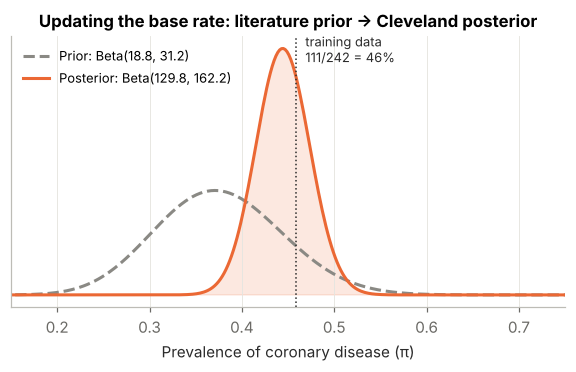

In [8]:
xs = np.linspace(0, 1, 500)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(xs, stats.beta(a0, b0).pdf(xs), color=COL["prior"], ls="--", label="Prior: Beta(18.8, 31.2)")
ax.plot(xs, stats.beta(a1, b1).pdf(xs), color=COL["M2"], label=f"Posterior: Beta({a1:.1f}, {b1:.1f})")
ax.fill_between(xs, stats.beta(a1, b1).pdf(xs), color=COL["M2"], alpha=0.15)
ax.axvline(k / n, color=INK, lw=1, ls=":")
ax.text(k / n + 0.01, ax.get_ylim()[1] * 0.9, f"training data\n{k}/{n} = {k/n:.0%}", fontsize=8.5, color=INK)
ax.set_xlim(0.15, 0.75); ax.set_yticks([]); ax.set_xlabel("Prevalence of coronary disease (π)")
ax.set_title("Updating the base rate: literature prior → Cleveland posterior")
ax.legend(loc="upper left", fontsize=8.5)
save(fig, "fig03_prevalence_prior_posterior"); plt.show()

### 2.2 Priors on the risk-factor effects

The diagnostic model is a logistic regression, so each prior is a Normal distribution on a **log odds ratio**.
Two prior sets are compared:

* **M1 – weakly informative:** every coefficient ~ $\mathcal{N}(0, 2.5^2)$, the default style suggested by
  Gelman et al. (2008). It only says "effects are probably not enormous".
* **M2 – literature informed:** means taken from published odds ratios and likelihood ratios, with standard
  deviations deliberately wide (0.3–0.75 on the log-odds scale) because the source populations differ from ours.

How a published number becomes a prior: a test with sensitivity *Se* and specificity *Sp* multiplies the
odds of disease by the positive likelihood ratio $LR^+ = Se/(1-Sp)$. On the log-odds scale this is an additive
shift, which is exactly what a logistic coefficient is. For example, Gianrossi et al. (1989) pooled 147 studies
of exercise ST depression and found Se ≈ 0.68 and Sp ≈ 0.77, so $LR^+ \approx 3$ and $\log 3 \approx 1.1$.
Since `oldpeak` is continuous and partly overlaps with `exang` and `slope`, we centre its prior at 0.6 per SD
rather than the full 1.1.

The intercept prior is centred on $\operatorname{logit}(0.376) = -0.51$, matching the base rate above,
because centring the predictors makes the intercept the log-odds for an "average" referred patient.

In [9]:
sources = {
    "age": "Diamond & Forrester (1979)", "sex": "Diamond & Forrester (1979)",
    "cp_atypical": "Diamond & Forrester (1979)", "cp_nonanginal": "Diamond & Forrester (1979)",
    "cp_asymptomatic": "No clear analogue; kept vague",
    "trestbps": "Judgement: small risk-factor effect", "chol": "Judgement: small risk-factor effect",
    "fbs": "Judgement: small risk-factor effect", "restecg_abn": "Judgement: small effect",
    "thalach": "Judgement, guided by Gianrossi et al. (1989)",
    "exang": "Judgement, guided by Gianrossi et al. (1989)", "oldpeak": "Gianrossi et al. (1989)",
    "slope_flat": "Judgement, guided by Gianrossi et al. (1989)",
    "slope_down": "Judgement, guided by Gianrossi et al. (1989)",
    "thal_fixed": "Knuuti et al. (2018)", "thal_reversible": "Knuuti et al. (2018)",
    "ca": "Judgement, guided by Knuuti et al. (2018)",
}
prior_table = pd.DataFrame([
    {"feature": f, "M1_mean": bh.WEAK.coefs[f][0], "M1_sd": bh.WEAK.coefs[f][1],
     "M2_mean": bh.LITERATURE.coefs[f][0], "M2_sd": bh.LITERATURE.coefs[f][1],
     "M2_prior_OR": np.exp(bh.LITERATURE.coefs[f][0]), "source": sources[f]}
    for f in bh.FEATURES])
prior_table.to_csv(RES / "prior_table.csv", index=False)
prior_table.round(2)

,feature,M1_mean,M1_sd,M2_mean,M2_sd,M2_prior_OR,source
0,age,0.0,2.5,0.40,0.30,1.49,Diamond & Forrester (1979)
1,trestbps,0.0,2.5,0.20,0.30,1.22,Judgement: small risk-factor effect
2,chol,0.0,2.5,0.20,0.30,1.22,Judgement: small risk-factor effect
3,thalach,0.0,2.5,-0.30,0.50,0.74,"Judgement, guided by Gianrossi et al. (1989)"
4,oldpeak,0.0,2.5,0.60,0.40,1.82,Gianrossi et al. (1989)
5,sex,0.0,2.5,0.92,0.50,2.51,Diamond & Forrester (1979)
6,fbs,0.0,2.5,0.30,0.50,1.35,Judgement: small risk-factor effect
7,exang,0.0,2.5,0.80,0.50,2.23,"Judgement, guided by Gianrossi et al. (1989)"
8,restecg_abn,0.0,2.5,0.20,0.50,1.22,Judgement: small effect
9,cp_atypical,0.0,2.5,-1.00,0.75,0.37,Diamond & Forrester (1979)


### 2.3 Prior predictive check

Before seeing any outcomes, what do the priors imply about predicted probabilities for our training patients?
A sensible prior should not claim that most patients are certainly sick or certainly healthy.

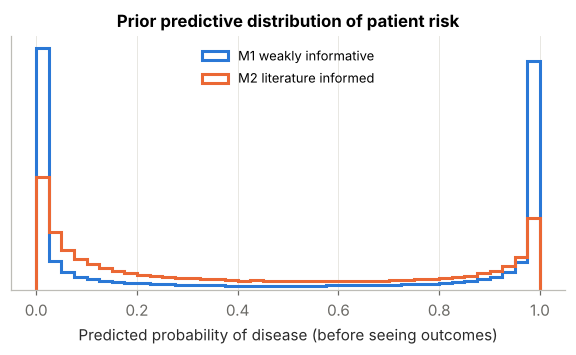

Share of prior predictions below 2% or above 98%: {'M1': '57%', 'M2': '20%'}


In [10]:
rng = np.random.default_rng(SEED)
def prior_predictive_probs(spec, X, n=2000):
    mu, sd = spec.arrays()
    a = rng.normal(spec.intercept[0], spec.intercept[1], n)
    b = rng.normal(mu, sd, size=(n, len(mu)))
    return expit(a[:, None] + b @ X.T).ravel()

pp = {"M1": prior_predictive_probs(bh.WEAK, P.X_train),
      "M2": prior_predictive_probs(bh.LITERATURE, P.X_train)}
fig, ax = plt.subplots(figsize=(6.5, 3.0))
bins = np.linspace(0, 1, 41)
for m, lab in [("M1", "M1 weakly informative"), ("M2", "M2 literature informed")]:
    ax.hist(pp[m], bins=bins, density=True, histtype="step", lw=2, color=COL[m], label=lab)
ax.set_xlabel("Predicted probability of disease (before seeing outcomes)"); ax.set_yticks([])
ax.set_title("Prior predictive distribution of patient risk")
ax.legend(loc="upper center", fontsize=8.5)
save(fig, "fig04_prior_predictive"); plt.show()
extreme = {m: float(np.mean((v < 0.02) | (v > 0.98))) for m, v in pp.items()}
print("Share of prior predictions below 2% or above 98%:", {m: f"{v:.0%}" for m, v in extreme.items()})
json.dump(extreme, open(RES / "prior_predictive_extremes.json", "w"))

The "vague" prior is not as harmless as it sounds. With 17 predictors, N(0, 2.5²) coefficients add up to
huge log-odds, so before seeing a single outcome M1 already puts most of its predictions below 2% or above 98%
(see the printed shares). The literature prior is still fairly open-minded, but it keeps far more of its mass
in the clinically plausible middle range.

## 3. Bayesian model development

$$
y_i \sim \text{Bernoulli}(p_i), \qquad
\operatorname{logit}(p_i) = \alpha + \sum_{j=1}^{17} \beta_j x_{ij}
$$

$$
\alpha \sim \mathcal{N}(\mu_\alpha, \sigma_\alpha^2), \qquad \beta_j \sim \mathcal{N}(\mu_j, \sigma_j^2)
$$

The posterior $p(\alpha, \beta \mid y, X) \propto p(y \mid X, \alpha, \beta)\,p(\alpha)\,p(\beta)$ has no closed form,
so we sample it with the No-U-Turn Sampler (NUTS): 4 chains × 2,000 draws after 1,500 tuning
steps. For a new patient $x^*$, the diagnosis is the **posterior predictive probability**

$$
P(y^*=1 \mid x^*, \text{data}) = \int \sigma(\alpha + \beta^\top x^*)\, p(\alpha,\beta \mid \text{data})\, d\alpha\, d\beta
\approx \frac{1}{S} \sum_{s=1}^{S} \sigma(\alpha^{(s)} + \beta^{(s)\top} x^*)
$$

and the spread of the $S$ values gives a credible interval for that patient's risk.

In [11]:
idata = {}
idata["M1"] = bh.fit(bh.build_model(P.X_train, P.y_train, bh.WEAK), seed=SEED)
idata["M2"] = bh.fit(bh.build_model(P.X_train, P.y_train, bh.LITERATURE), seed=SEED)

### 3.1 Convergence diagnostics

In [12]:
diag = pd.concat({m: az.summary(idata[m], var_names=["alpha", "beta"])[["mean", "sd", "hdi_3%", "hdi_97%", "r_hat", "ess_bulk"]]
                  for m in ["M1", "M2"]})
print("Max R-hat:", diag["r_hat"].max(), "| Min bulk ESS:", int(diag["ess_bulk"].min()))
print("Divergences:", {m: int(idata[m].sample_stats["diverging"].sum()) for m in idata})
diag.loc["M2"].round(3)

Max R-hat: 1.0 | Min bulk ESS: 4988
Divergences: {'M1': 0, 'M2': 0}


,mean,sd,hdi_3%,hdi_97%,r_hat,ess_bulk
alpha,-0.197,0.188,-0.557,0.149,1.0,12899.0
beta[age],0.105,0.183,-0.258,0.432,1.0,11488.0
beta[trestbps],0.235,0.167,-0.076,0.549,1.0,10034.0
beta[chol],0.207,0.171,-0.104,0.536,1.0,10916.0
beta[thalach],-0.324,0.221,-0.723,0.099,1.0,10259.0
beta[oldpeak],0.285,0.222,-0.122,0.710,1.0,10521.0
beta[sex],1.293,0.349,0.628,1.944,1.0,10453.0
beta[fbs],0.075,0.387,-0.668,0.765,1.0,11783.0
beta[exang],0.691,0.346,0.059,1.365,1.0,10401.0
beta[restecg_abn],0.337,0.308,-0.256,0.903,1.0,12936.0


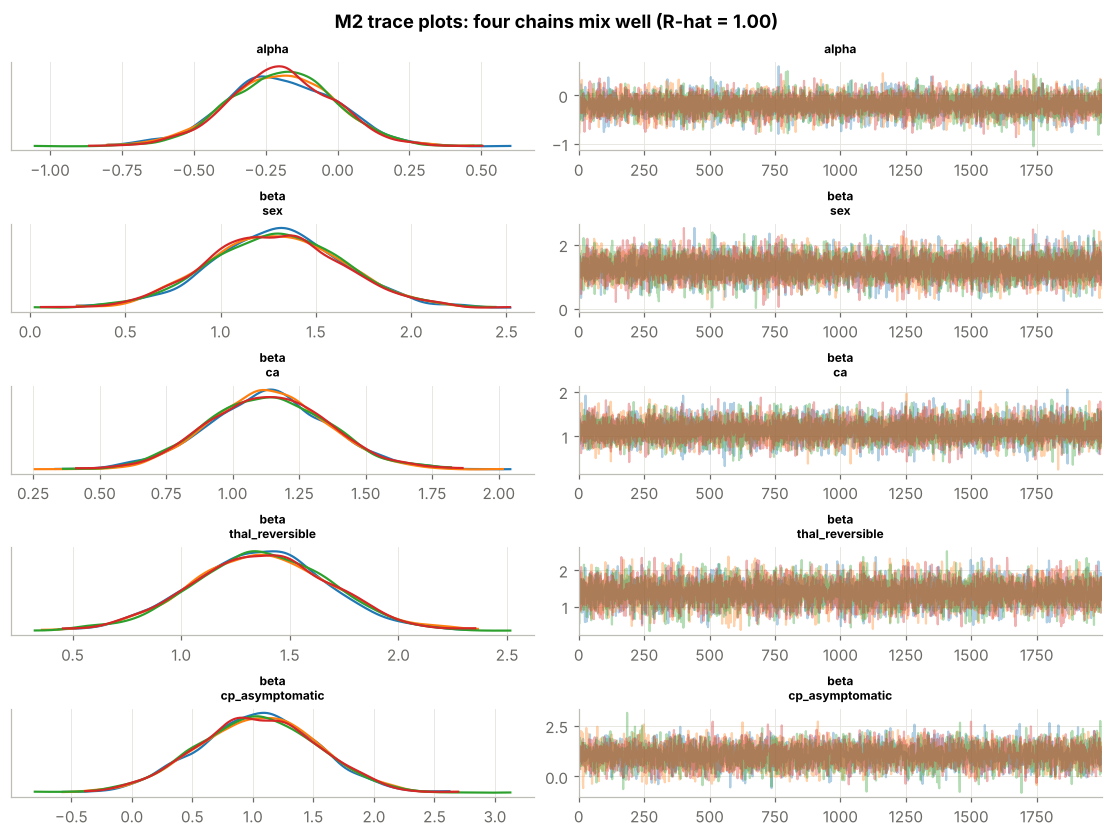

In [13]:
axes = az.plot_trace(idata["M2"], var_names=["alpha", "beta"],
                     coords={"feature": ["sex", "ca", "thal_reversible", "cp_asymptomatic"]},
                     compact=False, figsize=(10, 7.5), backend_kwargs={"layout": "constrained"})
fig = axes.ravel()[0].figure
fig.suptitle("M2 trace plots: four chains mix well (R-hat = 1.00)", fontweight="bold")
save(fig, "fig05_trace_M2"); plt.show()

### 3.2 Posterior distributions: how far did the data move the priors?

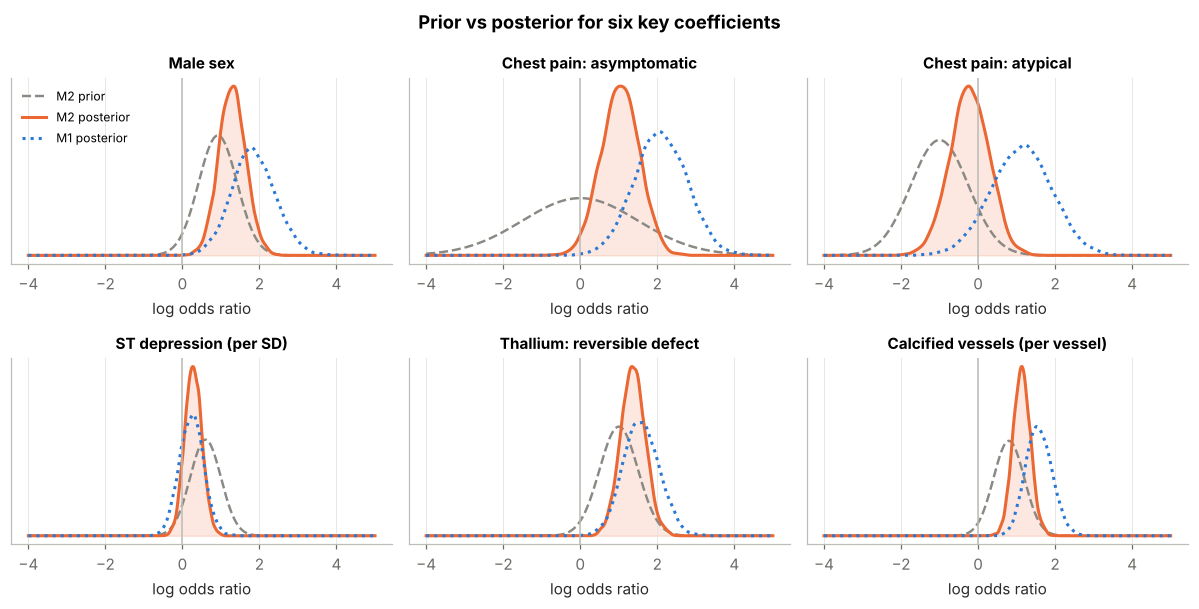

In [14]:
show = ["sex", "cp_asymptomatic", "cp_atypical", "oldpeak", "thal_reversible", "ca"]
pretty = {"sex": "Male sex", "cp_asymptomatic": "Chest pain: asymptomatic", "cp_atypical": "Chest pain: atypical",
          "oldpeak": "ST depression (per SD)", "thal_reversible": "Thallium: reversible defect",
          "ca": "Calcified vessels (per vessel)"}
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, f in zip(axes.ravel(), show):
    m, s = bh.LITERATURE.coefs[f]
    xs = np.linspace(-4, 5, 400)
    ax.plot(xs, stats.norm(m, s).pdf(xs), color=COL["prior"], ls="--", lw=1.6, label="M2 prior")
    for mod, ls in [("M2", "-"), ("M1", ":")]:
        d = idata[mod].posterior["beta"].sel(feature=f).values.ravel()
        kde = stats.gaussian_kde(d)
        ax.plot(xs, kde(xs), color=COL[mod], ls=ls, label=f"{mod} posterior")
        if mod == "M2":
            ax.fill_between(xs, kde(xs), color=COL[mod], alpha=0.15)
    ax.axvline(0, color="#bdbcb6", lw=1)
    ax.set_title(pretty[f], fontsize=10); ax.set_yticks([]); ax.set_xlabel("log odds ratio")
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Prior vs posterior for six key coefficients", fontweight="bold")
fig.tight_layout()
save(fig, "fig06_prior_vs_posterior"); plt.show()

## 4. Model validation on the 20% test set

Every metric uses the posterior predictive probability averaged over all 8,000 draws. A patient is called
"diseased" when that probability is at least 0.5. The **test log-likelihood** is the Bayesian
log pointwise predictive density, $\text{lppd} = \sum_i \log \frac{1}{S}\sum_s p(y_i \mid \theta^{(s)})$
(closer to 0 is better). A plain maximum-likelihood logistic regression (MLE) is included as a frequentist baseline.

In [15]:
mle = LogisticRegression(C=1e6, max_iter=5000).fit(P.X_train, P.y_train)
p_test = {"MLE": mle.predict_proba(P.X_test)[:, 1][None, :]}
for m in ["M1", "M2"]:
    p_test[m] = bh.predict_draws(idata[m], P.X_test)
first_round = pd.DataFrame({m: bh.evaluate(P.y_test, p) for m, p in p_test.items()}).T
first_round[["accuracy", "sensitivity", "specificity", "auc", "brier", "log_loss", "lppd"]].round(3)

,accuracy,sensitivity,specificity,auc,brier,log_loss,lppd
MLE,0.852,0.893,0.818,0.955,0.086,0.298,-18.148
M1,0.852,0.893,0.818,0.955,0.086,0.294,-17.916
M2,0.885,0.929,0.848,0.961,0.081,0.272,-16.590


Both Bayesian models are competitive with the unpenalised baseline; the literature-informed M2 is slightly
better on every metric. With only 61 test patients, though, one or two cases separate the models, so the
next section also uses leave-one-out cross-validation on the training data, which is far less noisy.

## 5. Iteration and refinement

### 5.1 Prior-data conflict check (training data only)

For each coefficient we compare what the training data say on their own (the M1 posterior, which is barely
influenced by its vague prior) with the literature prior:

$$ z_j = \frac{\hat\beta_j^{\,\text{data}} - \mu_j}{\sqrt{\text{sd}_{\text{data}}^2 + \sigma_j^2}} $$

A large |z| means the published effect and this dataset genuinely disagree. We use
a deliberately sensitive cut-off of |z| > 1.645 (two-sided p < 0.10). The test set is **not** used for this decision.

In [16]:
conflict = bh.prior_data_conflict(idata["M1"], bh.LITERATURE)
conflict["flag"] = conflict["z"].abs() > 1.645
conflict.to_csv(RES / "prior_data_conflict.csv", index=False)
flagged = conflict.loc[conflict["flag"], "feature"].tolist()
print("Flagged priors:", flagged)
conflict.sort_values("z", key=abs, ascending=False).round(2)

Flagged priors: ['cp_atypical', 'cp_nonanginal']


,feature,data_mean,data_sd,prior_mean,prior_sd,z,p_two_sided,flag
9,cp_atypical,1.12,0.78,-1.00,0.75,1.96,0.05,True
10,cp_nonanginal,0.22,0.70,-1.50,0.75,1.68,0.09,True
16,ca,1.58,0.34,0.80,0.40,1.49,0.14,False
0,age,-0.12,0.26,0.40,0.30,-1.31,0.19,False
11,cp_asymptomatic,2.09,0.69,0.00,1.50,1.27,0.21,False
5,sex,1.85,0.57,0.92,0.50,1.23,0.22,False
12,slope_flat,1.39,0.54,0.50,0.50,1.21,0.23,False
15,thal_reversible,1.58,0.47,1.00,0.50,0.85,0.39,False
6,fbs,-0.32,0.63,0.30,0.50,-0.77,0.44,False
4,oldpeak,0.24,0.31,0.60,0.40,-0.71,0.47,False


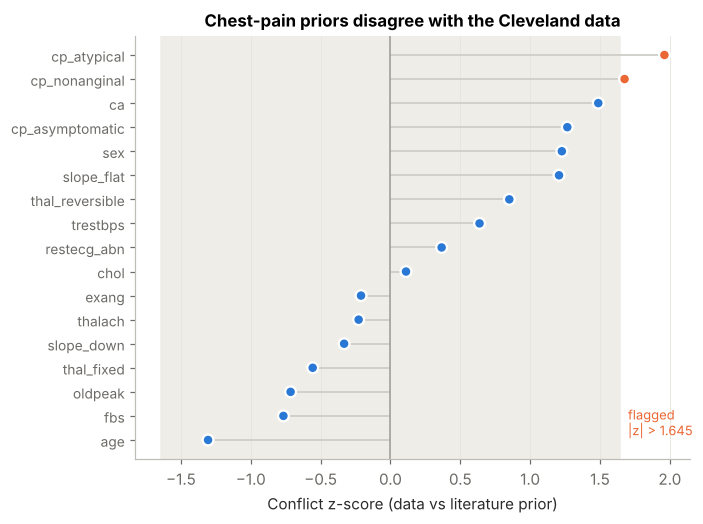

In [17]:
c = conflict.sort_values("z")
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.axvspan(-1.645, 1.645, color="#eeede8", zorder=0)
colors = [COL["M2"] if fl else COL["M1"] for fl in c["flag"]]
ax.hlines(range(len(c)), 0, c["z"], color="#cfcec8", lw=1.2)
ax.scatter(c["z"], range(len(c)), color=colors, s=50, zorder=3, edgecolor="white", linewidth=1.5)
ax.set_yticks(range(len(c))); ax.set_yticklabels(c["feature"], fontsize=9)
ax.axvline(0, color="#9b9a95", lw=1)
ax.set_xlabel("Conflict z-score (data vs literature prior)")
ax.set_title("Chest-pain priors disagree with the Cleveland data")
ax.text(1.7, 0.2, "flagged\n|z| > 1.645", color=COL["M2"], fontsize=8.5)
ax.grid(axis="y", visible=False)
save(fig, "fig07_prior_data_conflict"); plt.show()

Only the two chest-pain priors are flagged, and both in the same direction. The literature says atypical and
non-anginal pain should carry *lower* risk than typical angina, while in Cleveland the typical-angina group is
small (n = 23) and not especially high-risk. Several explanations are plausible: the dataset's chest-pain coding,
the way patients were referred, or simply small numbers. Either way, insisting on the published effect would
force the model to fight the data.

### 5.2 Refinements

* **M3 – adjusted priors.** The two conflicting priors are replaced by a neutral N(0, 1.5²). Everything else stays as in M2.
* **M4 – adjusted priors + modified likelihood.** Angiography is an imperfect reference standard, and a few
  labels in a 1980s research file may be wrong. M4 therefore uses a *mislabel-robust* likelihood
  $$P(y_i=1) = \varepsilon \cdot 0.5 + (1-\varepsilon)\,\sigma(\alpha + \beta^\top x_i), \qquad \varepsilon \sim \text{Beta}(1, 19)$$
  so a small share ε of outcomes can behave like coin flips instead of dragging the coefficients around.
  The Beta(1, 19) prior expects about 5% such cases.

In [18]:
SPEC_M3 = bh.refine_spec(bh.LITERATURE, flagged, widen_to=1.5, name="M3 refined priors")
idata["M3"] = bh.fit(bh.build_model(P.X_train, P.y_train, SPEC_M3), seed=SEED)
idata["M4"] = bh.fit(bh.build_model(P.X_train, P.y_train, SPEC_M3, robust=True), seed=SEED)
ROBUST = {"M1": False, "M2": False, "M3": False, "M4": True}
print(SPEC_M3.note)
print("Max R-hat (M3, M4):", float(az.summary(idata["M3"], var_names=["alpha", "beta"])["r_hat"].max()),
      float(az.summary(idata["M4"], var_names=["alpha", "beta", "eps"])["r_hat"].max()))
az.summary(idata["M4"], var_names=["eps"]).round(3)

Widened to N(0, 1.5): cp_atypical, cp_nonanginal
Max R-hat (M3, M4): 1.0 1.0


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
eps,0.037,0.028,0.0,0.087,0.0,0.0,5038.0,3160.0,1.0


### 5.3 Leave-one-out cross-validation (PSIS-LOO)

    rank  elpd_loo  p_loo  elpd_diff     se   dse  weight
M4     0    -94.69  10.84       0.00   9.07  0.00     1.0
M3     1    -95.25  11.77       0.56   9.55  0.71     0.0
M2     2    -96.50  11.55       1.81   9.77  1.65     0.0
M1     3   -101.32  19.89       6.63  11.56  3.29     0.0


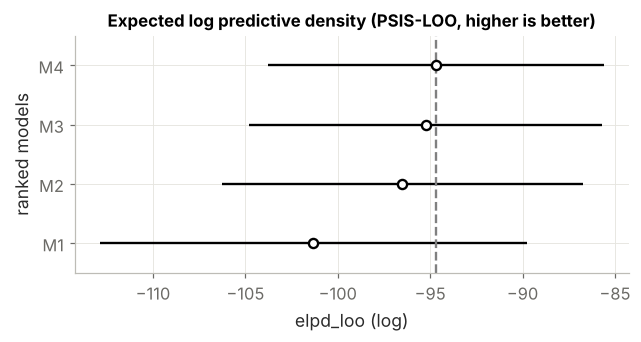

In [19]:
loo_cmp = az.compare({m: idata[m] for m in ["M1", "M2", "M3", "M4"]}, ic="loo")
loo_cmp.to_csv(RES / "loo_compare.csv")
print(loo_cmp[["rank", "elpd_loo", "p_loo", "elpd_diff", "se", "dse", "weight"]].round(2))
ax = az.plot_compare(loo_cmp, figsize=(6.5, 2.8), insample_dev=False)
ax.set_title("Expected log predictive density (PSIS-LOO, higher is better)")
save(ax.figure, "fig08_loo_compare"); plt.show()

The ranking is M4 > M3 > M2 > M1. Bringing in the literature (M1 → M2) gives the biggest jump and also cuts the
effective number of parameters (`p_loo`) from about 20 to about 12, i.e. the priors are doing real regularisation.
The refinements add smaller gains that sit inside one standard error, which is the honest size of the effect.
All Pareto-k values are below 0.7, so the LOO estimates are reliable.

### 5.4 Re-evaluation on the test set

In [20]:
for m in ["M3", "M4"]:
    p_test[m] = bh.predict_draws(idata[m], P.X_test, robust=ROBUST[m])
metrics = pd.DataFrame({m: bh.evaluate(P.y_test, p) for m, p in p_test.items()}).T
metrics.to_csv(RES / "test_metrics.csv")
metrics[["accuracy", "sensitivity", "specificity", "ppv", "npv", "f1", "auc", "auc_lo", "auc_hi",
         "brier", "log_loss", "lppd"]].round(3)

,accuracy,sensitivity,specificity,ppv,npv,f1,auc,auc_lo,auc_hi,brier,log_loss,lppd
MLE,0.852,0.893,0.818,0.806,0.900,0.847,0.955,0.892,0.995,0.086,0.298,-18.148
M1,0.852,0.893,0.818,0.806,0.900,0.847,0.955,0.890,0.996,0.086,0.294,-17.916
M2,0.885,0.929,0.848,0.839,0.933,0.881,0.961,0.906,0.997,0.081,0.272,-16.590
M3,0.885,0.929,0.848,0.839,0.933,0.881,0.962,0.906,0.998,0.080,0.274,-16.700
M4,0.885,0.929,0.848,0.839,0.933,0.881,0.962,0.906,0.998,0.081,0.277,-16.914


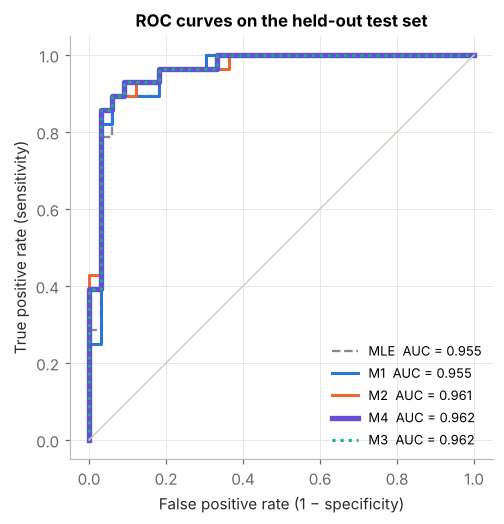

In [21]:
fig, ax = plt.subplots(figsize=(5.2, 5))
styles = {"MLE": ("--", 1.5), "M1": ("-", 2), "M2": ("-", 2), "M4": ("-", 3.5), "M3": (":", 2)}
for m in ["MLE", "M1", "M2", "M4", "M3"]:  # M3 drawn last and dotted: its curve sits on top of M4
    fpr, tpr, _ = roc_curve(P.y_test, p_test[m].mean(0))
    ls, lw = styles[m]
    ax.plot(fpr, tpr, color=COL[m], lw=lw, ls=ls, label=f"{m}  AUC = {metrics.loc[m, 'auc']:.3f}")
ax.plot([0, 1], [0, 1], color="#cfcec8", lw=1)
ax.set_xlabel("False positive rate (1 − specificity)"); ax.set_ylabel("True positive rate (sensitivity)")
ax.set_title("ROC curves on the held-out test set"); ax.legend(loc="lower right", fontsize=8.5)
ax.set_aspect("equal")
save(fig, "fig09_roc"); plt.show()

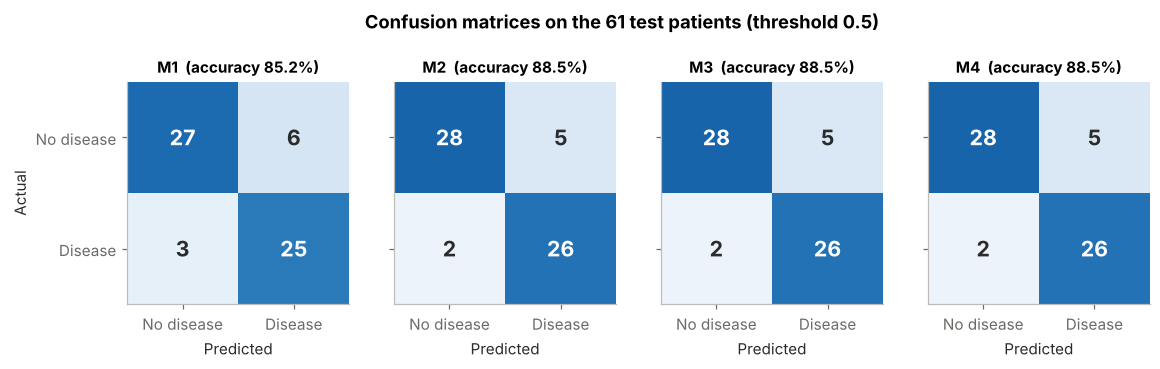

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.1))
for ax, m in zip(axes, ["M1", "M2", "M3", "M4"]):
    r = metrics.loc[m]
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]], dtype=int)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=35)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > 20 else INK, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No disease", "Disease"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["No disease", "Disease"] if m == "M1" else ["", ""])
    ax.set_xlabel("Predicted"); ax.set_title(f"{m}  (accuracy {r.accuracy:.1%})", fontsize=10)
    ax.grid(False)
axes[0].set_ylabel("Actual")
fig.suptitle("Confusion matrices on the 61 test patients (threshold 0.5)", fontweight="bold", y=1.03)
save(fig, "fig10_confusion"); plt.show()

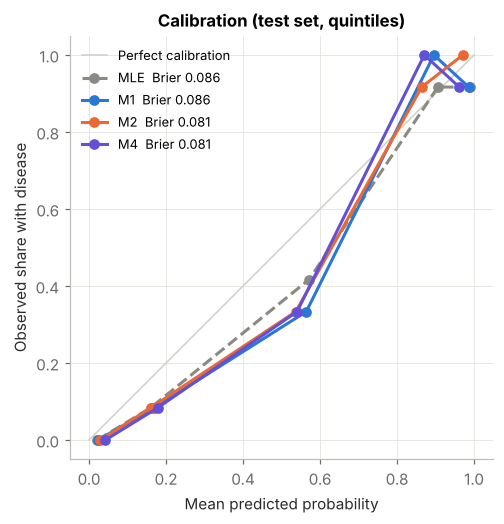

In [23]:
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color="#cfcec8", lw=1, label="Perfect calibration")
for m in ["MLE", "M1", "M2", "M4"]:
    pt, pp_ = calibration_curve(P.y_test, p_test[m].mean(0), n_bins=5, strategy="quantile")
    ax.plot(pp_, pt, marker="o", ms=6, color=COL[m], ls="--" if m == "MLE" else "-",
            label=f"{m}  Brier {metrics.loc[m, 'brier']:.3f}")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed share with disease")
ax.set_title("Calibration (test set, quintiles)"); ax.legend(loc="upper left", fontsize=8.5)
ax.set_aspect("equal")
save(fig, "fig11_calibration"); plt.show()

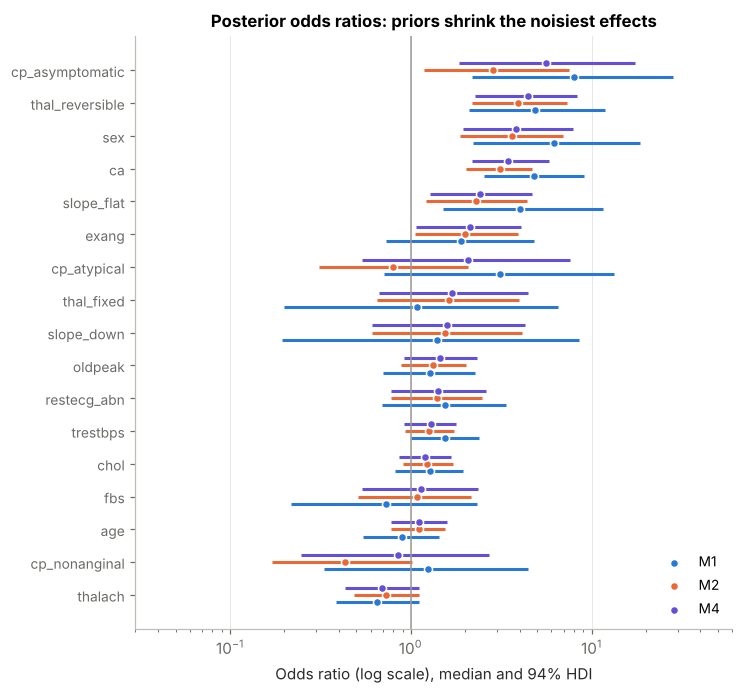

,model,feature,OR,lo,hi,p_positive
45,M4,cp_asymptomatic,5.61,1.84,17.45,1.00
49,M4,thal_reversible,4.48,2.27,8.29,1.00
39,M4,sex,3.82,1.95,7.90,1.00
50,M4,ca,3.45,2.17,5.82,1.00
46,M4,slope_flat,2.43,1.27,4.67,0.99
41,M4,exang,2.12,1.07,4.08,0.98
43,M4,cp_atypical,2.08,0.54,7.61,0.85
48,M4,thal_fixed,1.68,0.67,4.44,0.85
47,M4,slope_down,1.59,0.61,4.30,0.81
38,M4,oldpeak,1.45,0.92,2.32,0.94


In [24]:
# Odds ratios with 94% HDIs for M1, M2 and the final model M4
rows = []
for m in ["M1", "M2", "M4"]:
    b = idata[m].posterior["beta"]
    hdi = az.hdi(idata[m], var_names=["beta"])["beta"]
    for f in bh.FEATURES:
        rows.append({"model": m, "feature": f, "OR": float(np.exp(b.sel(feature=f).median())),
                     "lo": float(np.exp(hdi.sel(feature=f, hdi="lower"))),
                     "hi": float(np.exp(hdi.sel(feature=f, hdi="higher"))),
                     "p_positive": float((b.sel(feature=f) > 0).mean())})
or_table = pd.DataFrame(rows)
or_table.to_csv(RES / "odds_ratios.csv", index=False)

order = or_table[or_table.model == "M4"].sort_values("OR")["feature"].tolist()
fig, ax = plt.subplots(figsize=(7, 7))
for k_, (m, off) in enumerate([("M1", -0.22), ("M2", 0.0), ("M4", 0.22)]):
    d = or_table[or_table.model == m].set_index("feature").loc[order]
    y = np.arange(len(order)) + off
    ax.hlines(y, d["lo"], d["hi"], color=COL[m], lw=2)
    ax.scatter(d["OR"], y, color=COL[m], s=28, zorder=3, edgecolor="white", linewidth=1, label=m)
ax.axvline(1, color="#9b9a95", lw=1)
ax.set_xscale("log"); ax.set_xlim(0.03, 60)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=9)
ax.set_xlabel("Odds ratio (log scale), median and 94% HDI")
ax.set_title("Posterior odds ratios: priors shrink the noisiest effects")
ax.legend(loc="lower right", fontsize=9); ax.grid(axis="y", visible=False)
save(fig, "fig12_forest_odds_ratios"); plt.show()
or_table[or_table.model == "M4"].sort_values("OR", ascending=False).round(2)

### 5.5 Robustness check: 5-fold cross-validation on the full Cleveland cohort

A single 61-patient test set is a noisy referee. To check that the ranking is not an accident of one split,
every model is refitted on five stratified folds of all 303 patients (preprocessing is redone inside each fold).

In [25]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
specs = {"M1": (bh.WEAK, False), "M2": (bh.LITERATURE, False), "M3": (SPEC_M3, False), "M4": (SPEC_M3, True)}
for fold, (tr, te) in enumerate(skf.split(cle, cle["target"]), start=1):
    Pf = bh.prepare(cle.iloc[tr], cle.iloc[te])  # transforms refitted inside each fold
    Xtr, Xte, ytr, yte = Pf.X_train, Pf.X_test, Pf.y_train, Pf.y_test
    p = LogisticRegression(C=1e6, max_iter=5000).fit(Xtr, ytr).predict_proba(Xte)[:, 1][None, :]
    cv_rows.append({"fold": fold, "model": "MLE", **bh.evaluate(yte, p, n_boot=10)})
    for m, (spec, rob) in specs.items():
        idf = bh.fit(bh.build_model(Xtr, ytr, spec, robust=rob), draws=1000, tune=1000, seed=SEED + fold)
        p = bh.predict_draws(idf, Xte, robust=rob)
        cv_rows.append({"fold": fold, "model": m, **bh.evaluate(yte, p, n_boot=10)})
cv = pd.DataFrame(cv_rows)
cv.to_csv(RES / "cv_folds.csv", index=False)
cv_summary = cv.groupby("model")[["accuracy", "sensitivity", "specificity", "auc", "brier", "log_loss"]].agg(["mean", "std"])
cv_summary.to_csv(RES / "cv_summary.csv")
cv_summary.round(3)

accuracy        sensitivity        specificity           auc         \
          mean    std        mean    std        mean    std   mean    std   
model                                                                       
M1       0.851  0.039       0.791  0.042       0.903  0.049  0.912  0.021   
M2       0.845  0.041       0.806  0.040       0.879  0.060  0.919  0.024   
M3       0.855  0.034       0.784  0.038       0.915  0.039  0.917  0.023   
M4       0.855  0.029       0.784  0.038       0.915  0.039  0.918  0.023   
MLE      0.838  0.021       0.777  0.032       0.891  0.046  0.912  0.021   

       brier        log_loss         
        mean    std     mean    std  
model                                
M1     0.117  0.016    0.382  0.057  
M2     0.116  0.017    0.369  0.048  
M3     0.113  0.016    0.363  0.044  
M4     0.113  0.016    0.363  0.041  
MLE    0.119  0.016    0.388  0.056

## 6. Dynamic updating: yesterday's posterior is today's prior

A deployed diagnostic system does not see all its data at once. Bayes' rule handles this naturally:

$$ p(\theta \mid D_1, D_2) \propto p(D_2 \mid \theta)\, p(\theta \mid D_1) $$

Here the 242 training patients arrive in five batches. After each batch the joint posterior of
$(\alpha, \beta)$ is summarised by a multivariate Normal (mean vector and full covariance matrix) that becomes
the prior for the next batch. We start from the refined M3 priors and use the standard likelihood so the
Gaussian summary covers every parameter. After every update the model is scored on the same test set.

In [26]:
history = bh.sequential_update(P.X_train, P.y_train, SPEC_M3, P.X_test, P.y_test, n_batches=5, seed=SEED)
seq = pd.DataFrame([{"n_seen": h["n_seen"], **{k_: h["metrics"][k_] for k_ in ["accuracy", "auc", "log_loss", "brier", "lppd"]}}
                    for h in history])
names = ["intercept"] + bh.FEATURES
for f in ["sex", "ca", "thal_reversible", "cp_asymptomatic"]:
    j = names.index(f)
    seq[f + "_mean"] = [h["mean"][j] for h in history]
    seq[f + "_sd"] = [np.sqrt(h["cov"][j, j]) for h in history]
seq.to_csv(RES / "sequential_updates.csv", index=False)

# Does batch-by-batch learning end up where full-batch learning does?
full = idata["M3"].posterior
cmp_rows = []
for f in bh.FEATURES:
    j = names.index(f)
    cmp_rows.append({"feature": f, "sequential_mean": history[-1]["mean"][j],
                     "full_batch_mean": float(full["beta"].sel(feature=f).mean()),
                     "sequential_sd": np.sqrt(history[-1]["cov"][j, j]),
                     "full_batch_sd": float(full["beta"].sel(feature=f).std())})
seq_vs_full = pd.DataFrame(cmp_rows)
seq_vs_full.to_csv(RES / "sequential_vs_full.csv", index=False)
print("Max |difference| in posterior means:", seq_vs_full.eval("abs(sequential_mean - full_batch_mean)").max().round(3))
seq.round(3)

Max |difference| in posterior means: 0.058


,n_seen,accuracy,auc,log_loss,brier,lppd,sex_mean,sex_sd,ca_mean,ca_sd,thal_reversible_mean,thal_reversible_sd,cp_asymptomatic_mean,cp_asymptomatic_sd
0,0,0.885,0.942,0.361,0.106,-21.991,0.920,0.500,0.800,0.400,1.000,0.500,0.000,1.500
1,49,0.885,0.951,0.301,0.088,-18.389,1.293,0.461,0.954,0.330,1.307,0.444,0.812,0.876
2,98,0.918,0.960,0.285,0.082,-17.414,1.408,0.431,0.902,0.283,1.438,0.396,1.555,0.667
3,146,0.885,0.955,0.291,0.084,-17.735,1.404,0.405,1.176,0.253,1.402,0.379,1.618,0.635
4,194,0.885,0.959,0.278,0.083,-16.986,1.349,0.377,1.206,0.235,1.327,0.354,1.471,0.584
5,242,0.885,0.960,0.275,0.081,-16.772,1.378,0.365,1.146,0.228,1.382,0.337,1.643,0.564


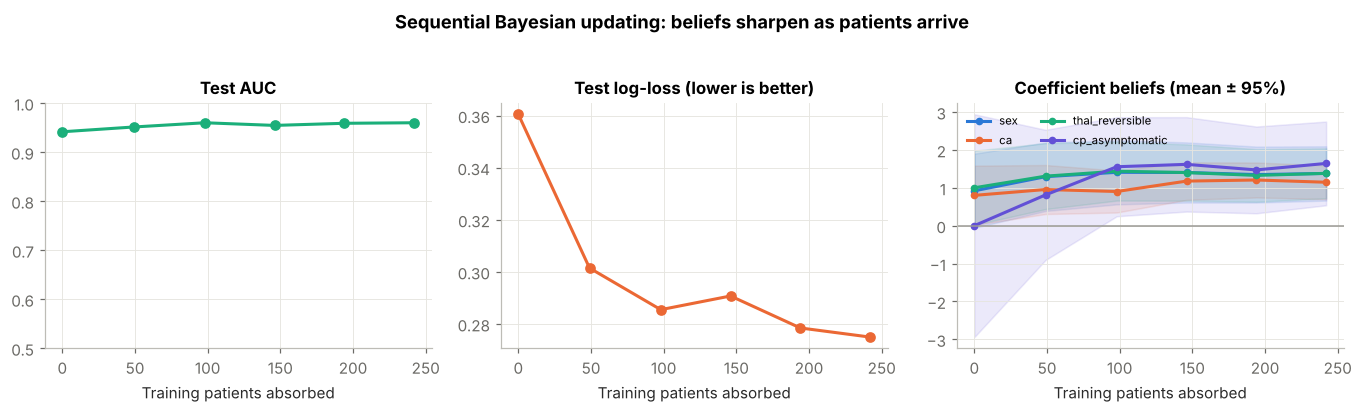

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
ax = axes[0]
ax.plot(seq["n_seen"], seq["auc"], marker="o", color=COL["M3"])
ax.set_title("Test AUC"); ax.set_xlabel("Training patients absorbed"); ax.set_ylim(0.5, 1)
ax = axes[1]
ax.plot(seq["n_seen"], seq["log_loss"], marker="o", color=COL["M2"])
ax.set_title("Test log-loss (lower is better)"); ax.set_xlabel("Training patients absorbed")
ax = axes[2]
for f, c in zip(["sex", "ca", "thal_reversible", "cp_asymptomatic"],
                [COL["M1"], COL["M2"], COL["M3"], COL["M4"]]):
    m_, s_ = seq[f + "_mean"], seq[f + "_sd"]
    ax.plot(seq["n_seen"], m_, color=c, marker="o", ms=4, label=f)
    ax.fill_between(seq["n_seen"], m_ - 1.96 * s_, m_ + 1.96 * s_, color=c, alpha=0.12)
ax.axhline(0, color="#9b9a95", lw=1)
ax.set_title("Coefficient beliefs (mean ± 95%)"); ax.set_xlabel("Training patients absorbed")
ax.legend(fontsize=7.5, loc="upper left", ncol=2)
fig.suptitle("Sequential Bayesian updating: beliefs sharpen as patients arrive", fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "fig13_sequential_updating"); plt.show()

### 6.1 What this means for a single patient

The figure below follows one test patient through the updates. With no data the model only knows the
literature, so its belief about this patient is wide. Each batch narrows it.

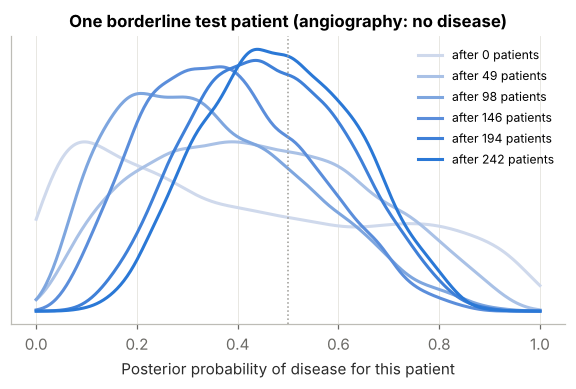

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,0.0,7.0,0


In [28]:
p_final = p_test["M4"]
mean_final = p_final.mean(0)
# Pick a borderline case: the test patient whose final prediction is closest to 0.5
pid = int(np.argmin(np.abs(mean_final - 0.5)))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
xs = np.linspace(0, 1, 300)
shades = ["#cfd9ec", "#a9c1e6", "#7ea6df", "#5b8edb", "#3f80d8", "#2a78d6"]
for h, c in zip(history, shades):
    d = h["p_eval"][:, pid]
    kde = stats.gaussian_kde(d)
    ax.plot(xs, kde(xs), color=c, label=f"after {h['n_seen']} patients")
ax.axvline(0.5, color="#9b9a95", lw=1, ls=":")
ax.set_xlabel("Posterior probability of disease for this patient"); ax.set_yticks([])
truth = "disease" if P.y_test[pid] == 1 else "no disease"
ax.set_title(f"One borderline test patient (angiography: {truth})")
ax.legend(fontsize=8, loc="upper right")
save(fig, "fig14_patient_updating"); plt.show()
P.raw_test.iloc[[pid]][bh.COLUMNS]

### 6.2 Using the system for a new patient

`diagnose()` turns a raw patient record into a posterior probability with a 95% credible interval, using the
final model M4 and the training-set preprocessing.

In [29]:
def diagnose(patient: dict, model="M4"):
    raw = pd.DataFrame([patient])
    X = P.transform(raw)
    p = bh.predict_draws(idata[model], X, robust=ROBUST[model])[:, 0]
    lo, hi = np.percentile(p, [2.5, 97.5])
    return {"posterior_probability": round(float(p.mean()), 3), "95%_CrI": (round(float(lo), 3), round(float(hi), 3))}

examples = {
    "55-year-old woman, non-anginal pain, normal tests":
        dict(age=55, sex=0, cp=3, trestbps=130, chol=230, fbs=0, restecg=0, thalach=160,
             exang=0, oldpeak=0.0, slope=1, ca=0, thal=3),
    "60-year-old man, asymptomatic, 1 mm ST depression, reversible defect":
        dict(age=60, sex=1, cp=4, trestbps=140, chol=250, fbs=0, restecg=2, thalach=135,
             exang=1, oldpeak=1.0, slope=2, ca=1, thal=7),
    "48-year-old man, atypical pain, flat ST slope, otherwise normal":
        dict(age=48, sex=1, cp=2, trestbps=125, chol=240, fbs=0, restecg=0, thalach=150,
             exang=0, oldpeak=0.8, slope=2, ca=0, thal=3),
}
example_out = pd.DataFrame({k_: diagnose(v) for k_, v in examples.items()}).T
example_out.to_csv(RES / "example_patients.csv")
example_out

,posterior_probability,95%_CrI
"55-year-old woman, non-anginal pain, normal tests",0.027,"(0.007, 0.059)"
"60-year-old man, asymptomatic, 1 mm ST depression, reversible defect",0.962,"(0.924, 0.986)"
"48-year-old man, atypical pain, flat ST slope, otherwise normal",0.207,"(0.07, 0.429)"


## 7. Save a compact summary for the report

In [30]:
summary = {
    "n_train": int(len(P.y_train)), "n_test": int(len(P.y_test)),
    "flagged_priors": flagged,
    "eps_mean": float(idata["M4"].posterior["eps"].mean()),
    "eps_hdi": [float(v) for v in az.hdi(idata["M4"], var_names=["eps"])["eps"].values],
    "borderline_patient_index": pid,
    "borderline_patient_final_mean": float(mean_final[pid]),
    "borderline_patient_truth": int(P.y_test[pid]),
    "borderline_patient_ci_width": [float(np.subtract(*np.percentile(h["p_eval"][:, pid], [97.5, 2.5]))) for h in history],
    "divergences": {m: int(idata[m].sample_stats["diverging"].sum()) for m in idata},
    "max_rhat": float(max(az.summary(idata[m], var_names=["alpha", "beta"])["r_hat"].max() for m in idata)),
    "min_ess": float(min(az.summary(idata[m], var_names=["alpha", "beta"])["ess_bulk"].min() for m in idata)),
    "p_loo": {m: float(loo_cmp.loc[m, "p_loo"]) for m in loo_cmp.index},
}
json.dump(summary, open(RES / "summary.json", "w"), indent=2)
summary

{'n_train': 242,
 'n_test': 61,
 'flagged_priors': ['cp_atypical', 'cp_nonanginal'],
 'eps_mean': 0.03669901352861635,
 'eps_hdi': [1.699951312175139e-05, 0.08709782306416711],
 'borderline_patient_index': 33,
 'borderline_patient_final_mean': 0.4959392697232463,
 'borderline_patient_truth': 0,
 'borderline_patient_ci_width': [0.9203961799488292,
  0.7722937506116823,
  0.6751064512232658,
  0.596226260327863,
  0.5752711702839994,
  0.5554449581021246],
 'divergences': {'M1': 0, 'M2': 0, 'M3': 0, 'M4': 0},
 'max_rhat': 1.0,
 'min_ess': 4854.0,
 'p_loo': {'M4': 10.843315242346549,
  'M3': 11.765544340719629,
  'M2': 11.547276799144512,
  'M1': 19.887493848977144}}

## 8. Take-aways

* Literature priors (M2) beat vague priors (M1) on LOO and on the test set, and in 5-fold cross-validation they
  give better AUC, Brier score and log-loss (accuracy is about the same). They also cut the effective number of
  parameters from about 20 to about 12.
* The conflict check caught the one place where the literature does not transfer to this dataset (chest-pain type),
  and relaxing those two priors helped.
* The robust likelihood (M4) gives the best LOO score and estimates that only about 3–4% of labels behave like noise,
  so the original labels are mostly trustworthy.
* Before seeing any Cleveland outcome, the literature priors alone already rank test patients with AUC ≈ 0.94.
* Sequential updating reaches essentially the same posterior as fitting all patients at once, which is what lets
  a deployed system keep learning as new cases arrive.

See the accompanying Word report for discussion, limitations and references.